In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import time

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
files = {}

for name in ["X_train", "X_test", "y_train", "y_test"]:
    matches = glob.glob(
        f"/kaggle/input/**/{name}.csv",
        recursive=True
    )

    if not matches:
        raise FileNotFoundError(f"{name}.csv not found!")

    files[name] = matches[0]

X_train = pd.read_csv(files["X_train"]).values
X_test = pd.read_csv(files["X_test"]).values

y_train = pd.read_csv(files["y_train"]).values.ravel()
y_test = pd.read_csv(files["y_test"]).values.ravel()

print("Data loaded successfully!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

Data loaded successfully!
X_train: (8929, 50)
X_test: (2233, 50)


In [3]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


def compute_loss(y_true, y_pred):
    epsilon = 1e-15

    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    return -np.mean(
        y_true * np.log(y_pred) +
        (1 - y_true) * np.log(1 - y_pred)
    )

In [4]:
def mini_batch_gradient_descent(
    X,
    y,
    learning_rate=0.01,
    epochs=100,
    batch_size=64,
    random_state=42
):

    n_samples, n_features = X.shape

    weights = np.zeros(n_features)
    bias = 0.0

    loss_history = []

    rng = np.random.default_rng(random_state)

    for epoch in range(epochs):

        # Shuffle training data
        indices = rng.permutation(n_samples)

        X_shuffled = X[indices]
        y_shuffled = y[indices]

        # Process mini-batches
        for start in range(0, n_samples, batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            # Forward pass
            z = np.dot(X_batch, weights) + bias
            y_pred = sigmoid(z)

            # Calculate gradients
            error = y_pred - y_batch

            dw = np.dot(X_batch.T, error) / len(y_batch)
            db = np.mean(error)

            # Update parameters
            weights -= learning_rate * dw
            bias -= learning_rate * db

        # Calculate loss after each epoch
        predictions = sigmoid(np.dot(X, weights) + bias)

        loss = compute_loss(y, predictions)

        loss_history.append(loss)

    return weights, bias, loss_history


print("Mini-Batch Gradient Descent created successfully!")

Mini-Batch Gradient Descent created successfully!


In [5]:
start_time = time.time()

weights_mbgd, bias_mbgd, loss_history_mbgd = (
    mini_batch_gradient_descent(
        X_train,
        y_train,
        learning_rate=0.01,
        epochs=100,
        batch_size=64
    )
)

training_time_mbgd = time.time() - start_time

print("Mini-Batch GD Training Completed!")
print("Final Training Loss:", loss_history_mbgd[-1])
print("Training Time:", round(training_time_mbgd, 4))

Mini-Batch GD Training Completed!
Final Training Loss: 0.5736182430738243
Training Time: 0.9104


In [6]:
def predict(X, weights, bias, threshold=0.5):

    probabilities = sigmoid(np.dot(X, weights) + bias)

    return (probabilities >= threshold).astype(int)


y_pred_mbgd = predict(
    X_test,
    weights_mbgd,
    bias_mbgd
)

print("Predictions generated successfully!")


Predictions generated successfully!


In [7]:
accuracy_mbgd = accuracy_score(y_test, y_pred_mbgd)
precision_mbgd = precision_score(y_test, y_pred_mbgd)
recall_mbgd = recall_score(y_test, y_pred_mbgd)
f1_mbgd = f1_score(y_test, y_pred_mbgd)

print("Mini-Batch Gradient Descent Results")
print("-----------------------------------")
print("Accuracy:", round(accuracy_mbgd, 4))
print("Precision:", round(precision_mbgd, 4))
print("Recall:", round(recall_mbgd, 4))
print("F1-Score:", round(f1_mbgd, 4))
print("Training Time:", round(training_time_mbgd, 4))

Mini-Batch Gradient Descent Results
-----------------------------------
Accuracy: 0.6941
Precision: 0.7198
Recall: 0.5803
F1-Score: 0.6426
Training Time: 0.9104


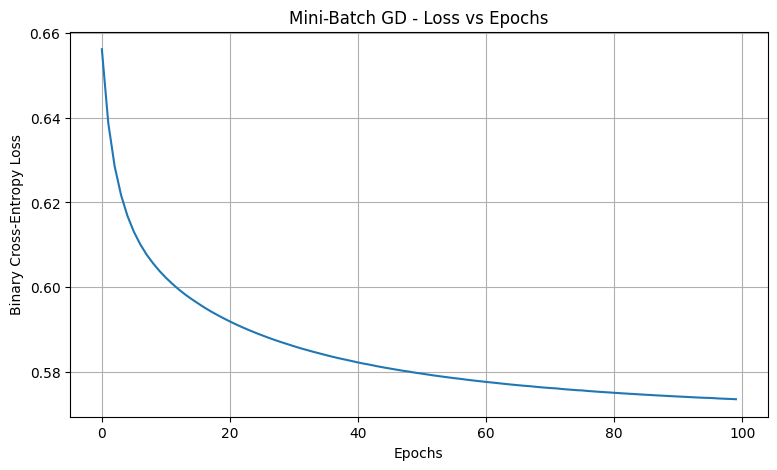

In [8]:
plt.figure(figsize=(9, 5))

plt.plot(loss_history_mbgd)

plt.title("Mini-Batch GD - Loss vs Epochs")
plt.xlabel("Epochs")
plt.ylabel("Binary Cross-Entropy Loss")

plt.grid(True)
plt.show()

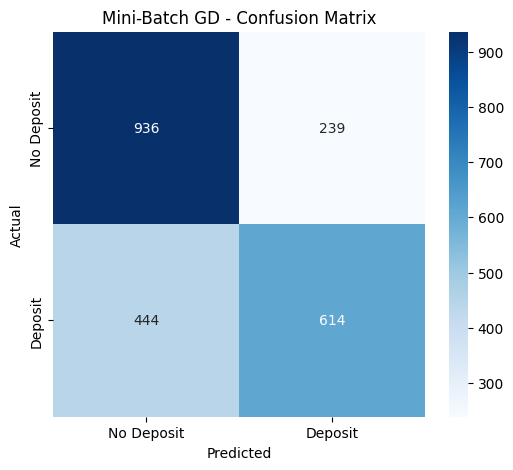

In [9]:
cm = confusion_matrix(y_test, y_pred_mbgd)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Deposit", "Deposit"],
    yticklabels=["No Deposit", "Deposit"]
)

plt.title("Mini-Batch GD - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()